# Chapter 08. 작은 데이터 분석 프로젝트 완성하기

## 제출 정보
- 이름: Jongeun Kim
- GitHub ID: risa0122
- 작성일: 2026-10-28
- 최종 Notebook URL: https://github.com/risa0122/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 1. 프로젝트 질문
### 분석 질문
1. 카테고리별 completed 주문 기준 금액과 판매 수량은 어떻게 다른가?
2. 월별 completed 주문 금액의 차이는 주문 수와 주문당 평균 금액에서 어떻게 나타나는가?
3. 구매 금액 상위 고객은 주문 횟수와 주문당 평균 금액에서 어떤 차이를 보이는가?

### 분석 범위
공식 공통 Raw의 전체 주문 기간을 사용한다. 금액 분석은 completed 주문만 포함하고 cancelled·refunded 주문은 제외한다. 고객 분석은 이 기간에 completed 주문이 있는 고객을 대상으로 한다.

### 사용할 데이터와 지표
| 질문 | 분석 대상·사용 데이터 | 지표 | 완료 기준 |
| --- | --- | --- | --- |
| 1 | 주문 상세의 수량·단가, 주문 상태, 상품 카테고리 | 카테고리별 금액·수량·금액 비중 | 범주별 합계가 completed 원본 합계와 일치 |
| 2 | 주문 상세 금액, 주문일·주문 ID·주문 상태 | 월별 금액, 고유 주문 수, 주문당 평균 금액 | 날짜 오류 0건, 월별 금액·주문 수의 총합 일치 |
| 3 | 주문 상세 금액, 주문·고객 ID 및 고객 연결 | 고객별 금액·고유 주문 수·주문당 평균 금액 | 고객별 총합 일치, 공개 결과에서 원본 ID·직접 식별정보 제외 |

### 계산 기준
- `order_status == "completed"` 적용 여부: 모든 금액성 집계에 동일하게 적용한다.
- `line_total = quantity × unit_price` 확인 여부: 원본 상세에서 재계산해 전처리 결과와 비교한다.
- 주문 수는 `order_id.nunique()`로 계산한다. 상세 행 수와 구분한다.
- `total_sales`는 완료 주문 상세 금액의 합계다. 실제 회사 매출액·순매출·이익을 의미하지 않는다. 금액은 원자료의 숫자 단위로 표시하며 통화를 별도로 가정하지 않는다.

### 완료 기준
PK 결측·중복 0건, FK 미매칭 0건, 병합 행 수 유지, 금액 계산 일치, completed 날짜 오류 0건을 확인한다. 카테고리·월·고객별 총합과 그래프 수치가 검증된 집계값과 같아야 한다. 공식 Validation 8개가 모두 PASS이고, 새 프로세스 재실행 결과도 일치해야 완료로 판단한다.

## 2. 입력 데이터와 전처리 검증
- 사용 원본 파일: `data/raw/customers.csv`, `products.csv`, `orders.csv`, `order_items.csv`.
- 출처: GilbertMoon/llm-data-analysis-course의 공통 Raw. 기준 버전은 `6105f42bd8294cb364dde6dcc2fee71c32e14794`다.
- Chapter 05 전용 오류 실습 자료와 구분한다. 따라서 Chapter 06·07 결과와의 차이를 전처리 개선 효과로 해석하지 않는다.
- 공식 Notebook의 분석 함수와 검증 흐름을 사용했다. 이전 과제와 파일이 섞이지 않도록 이 폴더를 실행 기준으로 삼았다.

처음 실행할 때만 고정 버전의 원본 4개를 내려받는다. 기존 파일의 체크섬이 다르면 덮어쓰지 않고 중단한다. 고객 원본과 내부 처리 CSV는 공개 저장소에 포함하지 않는다.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import subprocess
import sys
import tempfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

def find_project_root(start):
    start = Path(start).resolve()
    for parent in [start, *start.parents]:
        for candidate in [parent, parent / 'chapter08']:
            if (candidate / 'input_manifest.json').is_file() and (candidate / 'src/midterm_project.py').is_file():
                return candidate
    raise FileNotFoundError('chapter08 폴더를 찾을 수 없습니다.')

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))
from scripts.prepare_inputs import prepare_inputs
source_checks = prepare_inputs(PROJECT_ROOT)
RAW_DIR = PROJECT_ROOT / 'data/raw'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'
IMAGE_DIR = PROJECT_ROOT / 'images'
for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR, IMAGE_DIR]:
    path.mkdir(parents=True, exist_ok=True)
raw_hashes_before = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in RAW_DIR.glob('*.csv')}
pd.options.display.float_format = '{:,.2f}'.format
print('Python', platform.python_version(), '/ pandas', pd.__version__, '/ matplotlib', matplotlib.__version__)
print('원본 4개·공식 코드 6개 체크섬 검증:', len(source_checks), '개 PASS')

Python 3.12.14 / pandas 3.0.5 / matplotlib 3.11.1
원본 4개·공식 코드 6개 체크섬 검증: 10 개 PASS


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)

In [3]:
import src.midterm_project as project_module
assert Path(project_module.__file__).resolve() == PROJECT_ROOT / 'src/midterm_project.py'
from src.visualization import setup_korean_font
setup_korean_font()

def save_table_image(frame, filename, title):
    fig, ax = plt.subplots(figsize=(11.5, 1.1 + 0.43 * len(frame)))
    ax.axis('off')
    ax.set_title(title, loc='left', fontsize=13, pad=16)
    table = ax.table(cellText=frame.astype(str).values, colLabels=frame.columns,
                     loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.55)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor('#D1D5DB')
        cell.set_facecolor('#E8EFF7' if row == 0 else 'white')
    fig.tight_layout()
    fig.savefig(IMAGE_DIR / filename, dpi=150, bbox_inches='tight')
    plt.close(fig)

In [4]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))

,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


In [5]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)
preprocessing_comparison = compare_shapes(raw_data, processed_data)
preprocessing_comparison['removed_rows'] = (
    preprocessing_comparison['rows_raw'] - preprocessing_comparison['rows_processed'])
display(preprocessing_comparison)
display(build_key_duplicate_checks(raw_data))
checks_before = validate_relationships(raw_data)
checks_after = validate_relationships(processed_data)
assert checks_before['invalid_count'].eq(0).all()
assert checks_after['invalid_count'].eq(0).all()
assert preprocessing_comparison['removed_rows'].eq(0).all()
assert all(df.notna().all().all() for df in processed_data.values())
orders = processed_data['orders']
print('주문 상태:', orders['order_status'].value_counts().to_dict())
print('전체 주문 기간:', orders['order_date'].min().date(), '~', orders['order_date'].max().date())
save_table_image(dataset_summary, 'step02_data_validation.png', '입력 데이터 검증 — 실행 결과 요약')

,dataset,rows_raw,columns_raw,rows_processed,columns_processed,removed_rows
0,customers,150,6,150,6,0
1,order_items,764,5,764,6,0
2,orders,300,5,300,7,0
3,products,100,4,100,4,0


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


주문 상태: {'completed': 184, 'cancelled': 64, 'refunded': 52}
전체 주문 기간: 2025-07-09 ~ 2026-07-08


- shape: customers (150, 6), products (100, 4), orders (300, 5), order_items (764, 5).
- 핵심 결측/중복 결과: 원본의 결측 셀·완전 중복·PK 결측·PK 중복은 모두 0이다.
- 전처리 전후 변화: 네 파일 모두 행 수가 같다. 날짜·숫자 자료형을 정리하고 주문 월·요일, 상세 금액을 생성했다. 결측 대체나 행 제외는 실제로 발생하지 않았다.

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단
이 원본은 구조상 결측·중복이 없지만, 이를 가정하지 않고 전처리 전후에 다시 확인했다. 이번 실행은 행을 줄여 문제를 없앤 것이 아니라 같은 행을 유지하면서 계산·연결 관계를 확인한 결과다.

### 한계와 추가 확인 사항
실습용 가상 데이터이므로 실제 시장을 대표하지 않는다. 전체 주문 기간은 2025-07-09~2026-07-08로, 시작·종료 월은 한 달 전체를 포함하지 않는다. 날짜 변환 성공만으로 가입일과 주문일의 업무상 선후관계까지 검증된 것은 아니다.

## 3. PK/FK·병합 검증
### PK 결과
- 결측: 네 기본키 모두 0건.
- 중복: 네 기본키 모두 0건.
- PASS/FAIL: 모두 PASS.

### FK 결과
- 미매칭: 주문→고객, 상세→주문, 상세→상품 모두 0건.
- PASS/FAIL: 모두 PASS.

In [6]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")

,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


### 병합 결과
공식 `build_analysis_tables()`는 `indicator=True`로 미매칭을 확인하고, 아래 관계로 병합한다.

| 연결 | validate 관계 | 병합 전 행 수 | 병합 후 행 수 | 미매칭 | PASS/FAIL |
| --- | --- | ---: | ---: | ---: | --- |
| 전체 주문 상세 → 주문 | many_to_one | 764 | 764 | 0 | PASS |
| completed 상세 → 상품 | many_to_one | 474 | 474 | 0 | PASS |
| 고객별 집계 → 고객 정보 | one_to_one | 100 | 100 | 0 | PASS |

In [7]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")

,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.00,PASS


,scope,amount,detail_rows
0,all_order_items,"255,610,000.00",764
1,completed_order_items,"148,990,000.00",474
2,excluded_non_completed,"106,620,000.00",290


병합 / line_total Gate: PASS


In [8]:
completed = analysis_tables['completed_order_sales']
completed_order_count = completed['order_id'].nunique()
completed_ids = processed_data['orders'].loc[
    processed_data['orders']['order_status'].eq('completed'), 'order_id']
assert set(completed['order_id']) == set(completed_ids)
assert completed['order_status'].eq('completed').all()
assert completed['order_item_id'].is_unique
print('completed:', completed_order_count, '주문 /', len(completed), '상세 행')
print('전체 상세 금액:', f"{analysis_tables['order_sales']['line_total'].sum():,}")
print('completed 금액:', f"{completed['line_total'].sum():,}")

completed: 184 주문 / 474 상세 행
전체 상세 금액: 255,610,000
completed 금액: 148,990,000


### 나의 해석과 판단
주문 184건에 상세 474행이 연결된다. 상품 병합에서 행이 늘지 않았고, 완료 주문 ID도 빠지지 않았다. 전체 상세 금액 255,610,000과 completed 금액 148,990,000은 분석 범위가 다르다. 취소·환불 주문의 106,620,000을 포함하면 이번 질문의 금액을 과대 집계하게 된다.

## 4. 핵심 EDA 결과
### 결과 1
- 수치/표: 카테고리별 completed 금액·수량·비중.

In [9]:
category_sales = analysis_tables['category_sales']
monthly_sales = analysis_tables['monthly_sales']
customer_sales_internal = analysis_tables['customer_sales']
customer_sales_public = analysis_tables['customer_sales_public']
order_status_summary = analysis_tables['order_status_summary']
display(category_sales)

,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


- 결과 관찰: 스포츠의 금액은 31,743,000으로 가장 크며 비중은 21.31%, 수량은 295개다. 전자기기는 26,400,000, 생활용품은 23,915,000이다.
- 나의 해석과 판단: 스포츠는 현재 완료 주문 금액에서 가장 큰 비중을 차지한다. 다만 금액 순위는 수량과 단가가 함께 반영된 결과다.
- 업무·분석적 의미: 상품군별 실적을 점검할 때 금액 비중을 우선순위의 참고값으로 쓰고, 수량·단가를 분리해 확인할 수 있다.
- 한계: 원가·재고·방문 정보가 없어 수익성이나 인기 순위를 판단할 수 없다.

### 결과 2
- 수치/표: 월별 completed 금액·고유 주문 수·주문당 평균 금액.

In [10]:
display(monthly_sales)
assert monthly_sales['order_count'].sum() == completed_order_count
exact_aov = monthly_sales['total_sales'] / monthly_sales['order_count']
assert np.allclose(monthly_sales['avg_order_value'], exact_aov, rtol=0, atol=0.5)
month_periods = pd.PeriodIndex(monthly_sales['order_month'], freq='M')
calendar_months = pd.period_range(orders['order_date'].min(), orders['order_date'].max(), freq='M')
missing_months = calendar_months.difference(month_periods)
print('기간 안에 집계가 없는 월:', len(missing_months))
print('부분 관측 월:', str(calendar_months[0]), '/', str(calendar_months[-1]))

,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,"733,625.00"
1,2025-08,15621000,18,"867,833.00"
2,2025-09,10190000,13,"783,846.00"
3,2025-10,25766000,26,"991,000.00"
4,2025-11,8812000,12,"734,333.00"
5,2025-12,11501000,14,"821,500.00"
6,2026-01,17423000,22,"791,955.00"
7,2026-02,9749000,17,"573,471.00"
8,2026-03,13429000,14,"959,214.00"
9,2026-04,17553000,23,"763,174.00"


기간 안에 집계가 없는 월: 0
부분 관측 월: 2025-07 / 2026-07


- 결과 관찰: 2025년 10월 금액은 25,766,000으로 가장 크다. 26건의 주문이 있고 주문당 평균 금액은 991,000이다. 9월은 13건, 10,190,000, 주문당 약 783,846이다.
- 나의 해석과 판단: 9월보다 10월의 주문 수와 주문당 평균 금액이 모두 높다. 따라서 금액 차이를 주문 수만으로 설명하지 않는다.
- 업무·분석적 의미: 월별 금액 변화가 보이면 주문 수와 주문당 평균 금액을 같이 확인해 추가 분석 대상을 좁힐 수 있다.
- 한계: 시작·종료 월은 부분 관측이다. 2026년 7월 금액이 작다는 사실만으로 실적 악화라고 판단하지 않는다. 광고·프로모션·계절성의 원인은 이 자료로 확인할 수 없다.

### 결과 3
- 수치/표: 순위 기반 익명 고객 상위 10명의 completed 구매 금액과 주문 특성.

In [11]:
display(customer_sales_public.head(10))
top10_share = customer_sales_public.head(10)['total_sales'].sum() / completed['line_total'].sum() * 100
assert customer_sales_public['order_count'].sum() == completed_order_count
print('completed 구매 고객:', len(customer_sales_public))
print('상위 10명 금액:', f"{customer_sales_public.head(10)['total_sales'].sum():,}")
print('상위 10명 금액 비중:', f'{top10_share:.2f}%')
display(order_status_summary)

,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,"820,000.00"
1,Customer 02,고양,4,3996000,"999,000.00"
2,Customer 03,수원,4,3880000,"970,000.00"
3,Customer 04,서울,5,3590000,"718,000.00"
4,Customer 05,서울,4,3523000,"880,750.00"
5,Customer 06,인천,2,3191000,"1,595,500.00"
6,Customer 07,성남,2,3178000,"1,589,000.00"
7,Customer 08,광주,3,3153000,"1,051,000.00"
8,Customer 09,서울,4,3093000,"773,250.00"
9,Customer 10,부산,2,2990000,"1,495,000.00"


completed 구매 고객: 100
상위 10명 금액: 34,694,000
상위 10명 금액 비중: 23.29%


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


- 결과 관찰: 완료 구매 고객은 100명이며 상위 10명의 금액은 34,694,000, 전체의 23.29%다. Customer 01은 5건·4,100,000·주문당 820,000이다. Customer 06은 2건·3,191,000·주문당 1,595,500이다.
- 나의 해석과 판단: 금액 상위 고객에도 여러 차례 구매한 고객과 적은 횟수에 큰 금액을 구매한 고객이 함께 있다. 총액만으로 반복 구매 성향을 구분하기 어렵다.
- 업무·분석적 의미: 고객군을 점검할 때 총액과 구매 횟수, 주문당 금액을 함께 볼 필요가 있다.
- 한계: 관측 기간 이전·이후의 거래를 알 수 없으며 충성도·미래 가치·이탈 위험을 판단할 수 없다. 익명 라벨은 이번 정렬 순위여서 다른 실행·기간의 동일 고객 식별자로 쓰지 않는다.

## 5. Total consistency와 날짜 검증
공식 집계 결과 외에, 병합하지 않은 원본에서 completed 주문 ID에 속하는 상세를 다시 선택해 계산한다.

In [12]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")

,source,amount,difference_from_completed,matches_completed,status
0,completed_source,"148,990,000.00",0.00,True,PASS
1,category,"148,990,000.00",0.00,True,PASS
2,monthly,"148,990,000.00",0.00,True,PASS
3,customer,"148,990,000.00",0.00,True,PASS


Total consistency / Date Gate: PASS


In [13]:
raw_completed_ids = raw_data['orders'].loc[
    raw_data['orders']['order_status'].eq('completed'), 'order_id']
raw_completed = raw_data['order_items'].loc[
    raw_data['order_items']['order_id'].isin(raw_completed_ids)].copy()
independent_total = (raw_completed['quantity'] * raw_completed['unit_price']).sum()
assert independent_total == completed['line_total'].sum()
assert len(raw_completed) == len(completed)
assert set(raw_completed['order_item_id']) == set(completed['order_item_id'])
assert raw_completed['order_item_id'].is_unique and completed['order_item_id'].is_unique
assert category_sales['total_quantity'].sum() == raw_completed['quantity'].sum()
assert monthly_sales['order_count'].sum() == customer_sales_public['order_count'].sum() == len(raw_completed_ids)
assert orders['order_date'].notna().all()
assert orders['order_date'].le(pd.Timestamp('2026-10-28')).all()
display(analysis_tables['date_checks'])
print('병합 전 원본 독립 계산:', f'{independent_total:,}', '/ 상세 ID·행 수·수량·고유 주문 수 일치')

,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.00,PASS


병합 전 원본 독립 계산: 148,990,000 / 상세 ID·행 수·수량·고유 주문 수 일치


- completed source total: 148,990,000.
- category total: 148,990,000.
- monthly total: 148,990,000.
- customer total: 148,990,000.
- 총합 일치 여부: 네 합계와 병합 전 원본의 독립 계산값이 모두 같다.
- completed 주문 날짜 오류 건수: 0건(상세 행 기준 0행).
- 날짜 오류 영향 금액: 0.

### 불일치가 있었다면 원인
이번 원본에서는 불일치가 발생하지 않았다. 상세 ID·행 수와 고유 주문 수도 함께 비교해, 총액만 우연히 같은 경우를 추가 점검했다. 이 검증은 계산 범위의 일치를 의미하며 업무적 원인까지 검증하는 것은 아니다.

## 6. 대표 시각화
아래 그래프는 앞에서 검증한 집계표를 사용한다. 그래프 객체의 막대 높이·선의 좌표를 집계값과 직접 비교한 뒤 저장한다.

### 그래프 선택 이유
그래프 1은 카테고리별 금액을 내림차순 가로 막대로 비교한다. 길이가 긴 범주 이름을 읽기 쉽고, 0을 기준으로 크기 차이를 볼 수 있다.

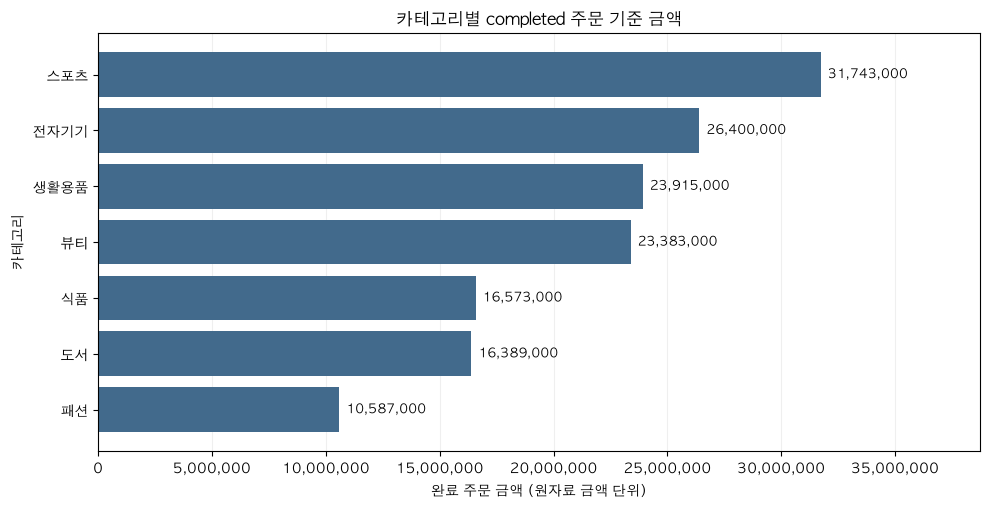

In [14]:
graph_checks = []
money_formatter = FuncFormatter(lambda value, position: f'{value:,.0f}')
plot_category = category_sales.sort_values('total_sales', ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.barh(plot_category['category'], plot_category['total_sales'], color='#426A8C')
assert np.array_equal([bar.get_width() for bar in bars], plot_category['total_sales'].to_numpy())
assert [t.get_text() for t in ax.get_yticklabels()] == plot_category['category'].tolist()
ax.bar_label(bars, labels=[f'{x:,.0f}' for x in plot_category['total_sales']], padding=5, fontsize=9)
ax.set_xlim(0, plot_category['total_sales'].max() * 1.22)
ax.set_title('카테고리별 completed 주문 기준 금액')
ax.set_xlabel('완료 주문 금액 (원자료 금액 단위)')
ax.set_ylabel('카테고리')
ax.xaxis.set_major_formatter(money_formatter)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'graph01.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
graph_checks.append({'그래프': '카테고리 막대', '대조': '범주 순서·막대 너비 = 집계 금액', '결과': 'PASS'})

### 그래프와 원본 집계값 일치 여부
7개 막대의 너비와 범주 순서를 집계표와 대조했다. 모두 일치하며 축은 0에서 시작한다.

### 그래프에서 직접 관찰한 사실
스포츠 31,743,000이 가장 크고 패션 10,587,000이 가장 작다.

나의 해석: 이번 완료 주문 금액에서 상품군의 기여가 다르다. 업무에서는 수량과 실제 주문 단가를 추가로 나누어 점검할 수 있다.

### 그래프만으로 말할 수 없는 것
금액이 크다는 이유로 해당 상품군이 더 인기 있거나 수익성이 높다고 말할 수 없다.

### 그래프 선택 이유
그래프 2는 시간 순서에 따른 금액과 주문 수를 별도 선그래프로 표시한다. 서로 단위가 다른 값을 한 축에 섞지 않는다.

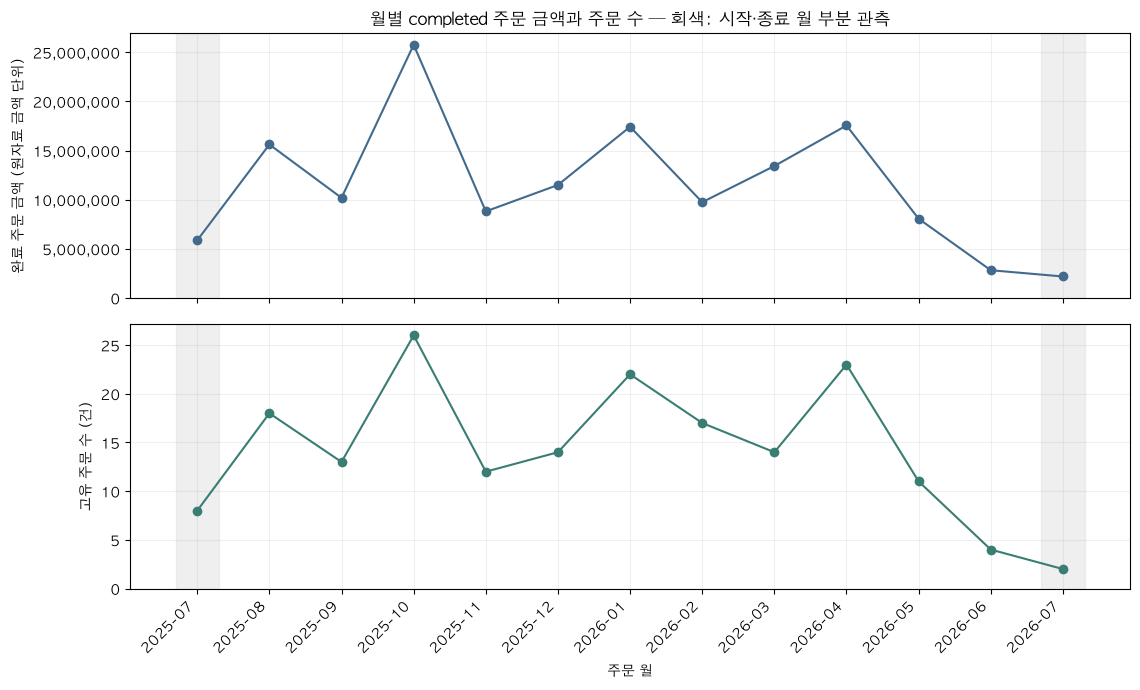

In [15]:
month_plot = monthly_sales.copy()
month_plot.index = pd.PeriodIndex(month_plot['order_month'], freq='M')
month_plot = month_plot.reindex(calendar_months)
# 집계가 없는 월은 0으로 채우지 않는다.
x = np.arange(len(month_plot))
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7), sharex=True)
for ax, column, label, color in [
    (axes[0], 'total_sales', '완료 주문 금액 (원자료 금액 단위)', '#426A8C'),
    (axes[1], 'order_count', '고유 주문 수 (건)', '#397D73')]:
    line, = ax.plot(x, month_plot[column].to_numpy(dtype=float), marker='o', color=color)
    assert np.allclose(line.get_ydata(), month_plot[column].to_numpy(dtype=float), equal_nan=True)
    assert np.array_equal(line.get_xdata(), x)
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.axvspan(-0.3, 0.3, color='#D9D9D9', alpha=0.4)
    ax.axvspan(len(x)-1.3, len(x)-0.7, color='#D9D9D9', alpha=0.4)
axes[0].yaxis.set_major_formatter(money_formatter)
axes[0].set_title('월별 completed 주문 금액과 주문 수 — 회색: 시작·종료 월 부분 관측')
axes[1].set_xticks(x, month_plot.index.astype(str), rotation=45, ha='right')
axes[1].set_xlabel('주문 월')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'graph02.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
graph_checks.append({'그래프': '월별 선', '대조': '13개월 시간 순서·선 좌표 = 월별 금액·주문 수', '결과': 'PASS'})

### 그래프와 원본 집계값 일치 여부
13개월의 금액·주문 수와 선 좌표를 대조했다. 기간 내 집계가 없는 월은 0개다. 향후 빈 월이 생기면 실제 0으로 채우지 않고 결측으로 남긴다. 회색 영역은 2025년 7월과 2026년 7월의 부분 관측 구간이다.

### 그래프에서 직접 관찰한 사실
2025년 10월은 금액 25,766,000, 주문 26건으로 두 지표 모두 가장 크다. 2026년 7월은 2,188,000, 2건이다.

나의 해석: 같은 금액 지표라도 주문 수와 주문당 금액을 함께 봐야 한다. 업무상 월별 점검에는 관측 기간이 같은지 확인하는 절차가 필요하다.

### 그래프만으로 말할 수 없는 것
선의 하락만으로 수요 감소나 마케팅 실패를 판단할 수 없다. 시작·종료 월의 낮은 값은 한 달 전체 값과 직접 비교할 수 없다.

### 그래프 선택 이유
그래프 3은 금액 상위 10명만 익명 라벨로 표시한다. 주문 수와 주문당 평균 금액은 앞의 고객 집계표와 함께 해석한다.

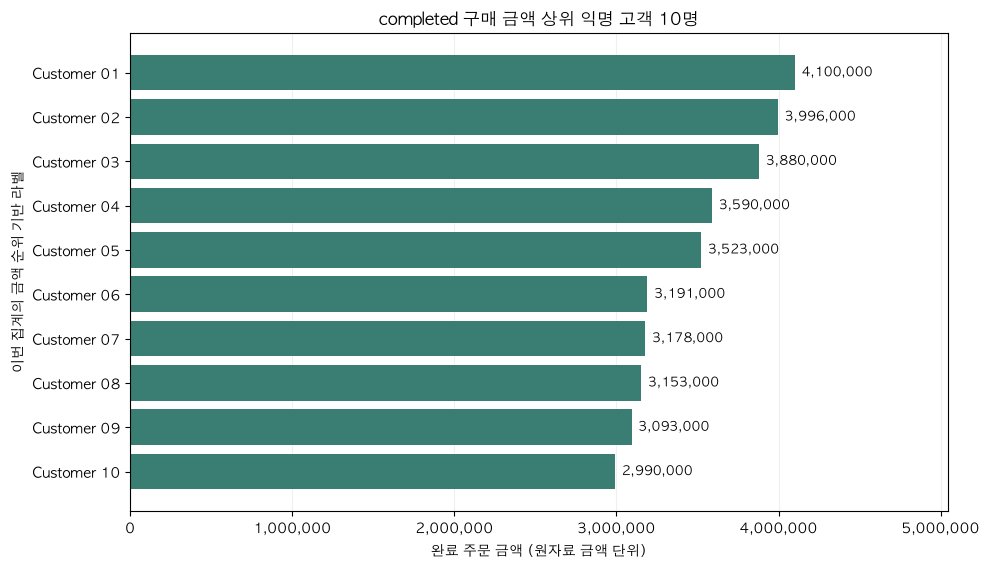

,그래프,대조,결과
0,카테고리 막대,범주 순서·막대 너비 = 집계 금액,PASS
1,월별 선,13개월 시간 순서·선 좌표 = 월별 금액·주문 수,PASS
2,상위 익명 고객 막대,순위 라벨·막대 너비 = 공개 집계값,PASS


In [16]:
top_customers = customer_sales_public.head(10).sort_values('total_sales')
fig, ax = plt.subplots(figsize=(10, 5.8))
bars = ax.barh(top_customers['customer_label'], top_customers['total_sales'], color='#397D73')
assert np.array_equal([bar.get_width() for bar in bars], top_customers['total_sales'].to_numpy())
assert [t.get_text() for t in ax.get_yticklabels()] == top_customers['customer_label'].tolist()
ax.bar_label(bars, labels=[f'{x:,.0f}' for x in top_customers['total_sales']], padding=5, fontsize=9)
ax.set_xlim(0, top_customers['total_sales'].max() * 1.23)
ax.set_title('completed 구매 금액 상위 익명 고객 10명')
ax.set_xlabel('완료 주문 금액 (원자료 금액 단위)')
ax.set_ylabel('이번 집계의 금액 순위 기반 라벨')
ax.xaxis.set_major_formatter(money_formatter)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'graph03.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
graph_checks.append({'그래프': '상위 익명 고객 막대', '대조': '순위 라벨·막대 너비 = 공개 집계값', '결과': 'PASS'})
display(pd.DataFrame(graph_checks))

### 그래프와 원본 집계값 일치 여부
상위 10명의 공개 집계값과 막대 너비·익명 라벨의 순서를 대조했다. 모두 일치한다.

### 그래프에서 직접 관찰한 사실
상위 10명의 금액은 2,990,000~4,100,000이며 합계 비중은 23.29%다.

나의 해석: 상위 금액 고객도 구매 횟수에 차이가 있다. 고객군을 살필 때 총액에만 의존하지 않고 횟수·주문당 금액을 함께 쓰는 것이 적절하다.

### 그래프만으로 말할 수 없는 것
상위 고객의 충성도·이탈 가능성·미래 가치를 나타내는 그래프가 아니다. 상위 10명만 그린 그림을 전체 고객 분포로 일반화하지 않는다.

## 7. 개인정보 검증
- 공개 고객 CSV 컬럼: customer_label, city, order_count, total_sales, avg_order_value.
- 원본 `customer_id` 포함 여부: 제외.
- 이름/이메일/전화번호/주소 포함 여부: 제외.
- 익명 라벨 방식: 구매 금액 순위에 따른 Customer 01, Customer 02 등. 원본 ID를 붙이지 않는다.
- PASS/FAIL: 메모리의 공개 표와 저장 후 다시 읽은 CSV 모두 PASS.

In [17]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")

공개 결과 금지 컬럼: []
Privacy Gate: PASS


In [18]:
interpretation_notes = build_interpretation_notes()
saved_tables = save_project_tables(
    dataset_summary, preprocessing_comparison, key_duplicate_checks,
    relationship_checks, analysis_tables, interpretation_notes, REPORT_DIR)
saved_customer = pd.read_csv(REPORT_DIR / 'ch08_customer_sales.csv')
allowed_columns = ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
assert saved_customer.columns.tolist() == allowed_columns
assert not FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
assert saved_customer['customer_label'].tolist() == [f'Customer {i:02d}' for i in range(1, len(saved_customer)+1)]
pd.testing.assert_frame_equal(saved_customer, customer_sales_public, check_dtype=False)
print('저장 CSV 컬럼:', saved_customer.columns.tolist())
print('원본 고객 ID·직접 식별정보 제외 / 순위 라벨 / 저장 후 재검증: PASS')

저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
원본 고객 ID·직접 식별정보 제외 / 순위 라벨 / 저장 후 재검증: PASS


### 나의 판단
내부 연결용 고객 ID와 공개 결과를 구분했다. 익명 라벨은 분석 결과를 읽기 위한 임시 이름이며, 실제 데이터에서 재식별 위험까지 없어진다는 뜻은 아니다. 원본 고객 행이나 ID 대응표는 제출하지 않는다.

## 8. 최종 Validation

In [19]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")

,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.00,100.00,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


In [20]:
saved_validation = pd.read_csv(REPORT_DIR / 'ch08_project_validation.csv')
assert saved_validation['status'].eq('PASS').all()
print('저장된 reports/ch08_project_validation.csv:', len(saved_validation), '개 모두 PASS')

저장된 reports/ch08_project_validation.csv: 8 개 모두 PASS


| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | 4개 기본키의 결측·중복 0건 |
| fk_integrity | PASS | 3개 연결의 미매칭 0건 |
| merge_checks_pass | PASS | 764→764, 474→474, 100→100; 미매칭 0건 |
| line_total_consistency | PASS | 수량×단가와 불일치 0건 |
| completed_total_consistency | PASS | 4개 합계 및 병합 전 원본 독립 계산 148,990,000 |
| category_sales_ratio_pct_sum | PASS | 비중 합계 100.00% |
| completed_rows_with_invalid_order_date | PASS | 날짜 오류 0행, 영향 금액 0 |
| public_customer_columns_safe | PASS | 저장 CSV 재로딩 후 금지 컬럼 없음 |

### FAIL이 있었다면 수정 내용
이번 공식 공통 Raw에서는 필수 검증 FAIL이 발생하지 않았다. 기존 과제의 다른 데이터로 얻은 결과를 덮어쓰거나 FAIL 행을 임의로 삭제하지 않았다. PASS는 정해 둔 구조·계산 검증의 통과이며, 모든 업무적 오류와 해석의 타당성을 보장하지 않는다.

## 9. LLM 활용 기록
- 사용 여부: Codex 사용.
- 사용 목적: 공식 코드의 실행 순서 정리, 검증 코드 보완, 그래프 구성과 해석 초안 작성.
- Safe Context: 질문, 컬럼 구조, 집계값, PK/FK·병합·총합 검증표, 익명 고객 결과를 사용했다. 원본 고객 행·이름·원본 ID 값은 대화에 제공하지 않았다.
- Prompt 요약: Chapter 08 요구사항과 답안 양식에 맞춰 분석하고, 필요한 확인 사항만 간단히 안내하도록 요청했다.
- 제안 요약: 카테고리·월·고객별 분석을 같은 completed 범위로 통일하고 원본 독립 합계, 그래프 수치 대조, 새 프로세스 재실행을 추가한다.
- 반영/수정/보류: 공식 함수를 유지했다. 금액의 통화는 임의로 단정하지 않고, 부분 관측 월을 표시했다. 인기·수익성·마케팅 효과·충성도에 대한 단정은 사용하지 않았다.
- 사람이 검증한 근거: 확인 대상은 3·5·6·8·10절의 실행표와 수치다. 현재 기록은 코드 실행·자동 대조 결과이며, 제출자 본인의 최종 검토를 자동 검증으로 대신했다고 주장하지 않는다.

## 10. 프로젝트 재현 확인
`chapter08` 폴더에서 `python scripts/run_midterm_project.py`를 실행한다. 아래 셀은 Notebook과 같은 Python으로 새 프로세스를 실행하고, 별도 출력 폴더에서 다시 실행해 비교한다. 원본 4개를 읽는 단계부터 시작한다.

In [21]:
# 공식 그래프와 보고서를 생성한다.
saved_figures = create_project_figures(analysis_tables, FIGURE_DIR, show=False)
report_text = build_midterm_report(dataset_summary, preprocessing_comparison,
    key_duplicate_checks, relationship_checks, analysis_tables, interpretation_notes)
report_path = REPORT_DIR / 'ch08_midterm_report.md'
report_path.write_text(report_text, encoding='utf-8')
print('공식 결과표·그래프·보고서 생성 완료')

공식 결과표·그래프·보고서 생성 완료


In [22]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")

ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


In [23]:
runtime_dir = PROJECT_ROOT / '.runtime'
runtime_dir.mkdir(exist_ok=True)
environment = dict(os.environ, MPLBACKEND='Agg')
command = [sys.executable, 'scripts/run_midterm_project.py']
run1 = subprocess.run(command, cwd=PROJECT_ROOT, env=environment,
                      capture_output=True, text=True, timeout=120)
print('실행: python scripts/run_midterm_project.py')
print(run1.stdout)
assert run1.returncode == 0, run1.stderr

for name, frame in [('category', category_sales), ('monthly', monthly_sales), ('customer', customer_sales_public)]:
    saved = pd.read_csv(REPORT_DIR / f'ch08_{name}_sales.csv')
    pd.testing.assert_frame_equal(saved, frame, check_dtype=False)
assert pd.read_csv(REPORT_DIR / 'ch08_project_validation.csv')['status'].eq('PASS').all()

with tempfile.TemporaryDirectory(prefix='rerun_', dir=runtime_dir) as temporary:
    run2 = subprocess.run(command + ['--output-root', temporary], cwd=PROJECT_ROOT,
                          env=environment, capture_output=True, text=True, timeout=120)
    assert run2.returncode == 0, run2.stderr
    second_report_dir = Path(temporary) / 'reports'
    comparison_rows = []
    for first in sorted(REPORT_DIR.rglob('*')):
        if not first.is_file():
            continue
        second = second_report_dir / first.relative_to(REPORT_DIR)
        assert second.is_file(), first.name
        equal = hashlib.sha256(first.read_bytes()).digest() == hashlib.sha256(second.read_bytes()).digest()
        comparison_rows.append({'file': str(first.relative_to(REPORT_DIR)), '동일': equal})
    assert len(comparison_rows) == 19
    assert all(row['동일'] for row in comparison_rows)

raw_hashes_after = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in RAW_DIR.glob('*.csv')}
assert raw_hashes_after == raw_hashes_before
prepare_inputs(PROJECT_ROOT)
reproduction = pd.DataFrame([
    ['새 프로세스 전체 실행', '2회 모두 종료 코드 0'],
    ['Notebook·스크립트 집계', '카테고리·월·공개 고객 표 일치'],
    ['공식 산출물', 'CSV 15개·그래프 3개·보고서 1개'],
    ['두 실행의 산출물', '19개 파일 체크섬 모두 동일'],
    ['원본 보존', 'CSV 4개 체크섬 유지'],
    ['최종 Validation', '8개 모두 PASS'],
], columns=['확인', '결과'])
display(reproduction)
save_table_image(reproduction, 'step06_reproduce.png', '프로젝트 재실행 — 실제 실행 결과 요약')

실행: python scripts/run_midterm_project.py
[최종 Validation]
                                 check                value             expected status
                          pk_integrity             all PASS             all PASS   PASS
                          fk_integrity                    0                    0   PASS
                     merge_checks_pass             all PASS             all PASS   PASS
                line_total_consistency                    0                    0   PASS
           completed_total_consistency            all match            all match   PASS
          category_sales_ratio_pct_sum                100.0                100.0   PASS
completed_rows_with_invalid_order_date                    0                    0   PASS
          public_customer_columns_safe no forbidden columns no forbidden columns   PASS
[총합 검증]
          source      amount  difference_from_completed  matches_completed status
completed_source 148990000.0                        0.0     

,확인,결과
0,새 프로세스 전체 실행,2회 모두 종료 코드 0
1,Notebook·스크립트 집계,카테고리·월·공개 고객 표 일치
2,공식 산출물,CSV 15개·그래프 3개·보고서 1개
3,두 실행의 산출물,19개 파일 체크섬 모두 동일
4,원본 보존,CSV 4개 체크섬 유지
5,최종 Validation,8개 모두 PASS


- `python scripts/run_midterm_project.py` 실행 여부: 새 프로세스에서 2회 실행했다.
- 재실행 결과: 두 번 모두 정상 종료했고 원본 체크섬이 유지됐다.
- Notebook과 핵심 수치 일치 여부: 카테고리·월·공개 고객 집계표가 같다.
- 생성된 핵심 Evidence 파일 확인 여부: CSV 15개·공식 그래프 3개·보고서 1개, 총 19개가 생성됐다. 두 실행의 파일 체크섬도 같다.

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단
일부 셀만 실행한 메모리 상태에 의존하지 않고, 같은 원본에서 같은 결과가 나오는지 확인했다. 오류가 발생하면 원본·코드·검증표를 다시 대조할 수 있다. 재현 성공이 인과 해석까지 맞다는 뜻은 아니다.

## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. **상품군 기여 차이:** 스포츠 금액 31,743,000, 비중 21.31%로 가장 높다. 현재 완료 주문 금액의 기여가 크다는 뜻이다. 카테고리 집계와 원본 총합 일치가 근거이며, 수량·단가를 나눠 볼 가치가 있다. 인기·수익성은 판단하지 못한다.
2. **월별 변화의 구성:** 2025년 10월은 9월보다 주문 수(13→26건)와 주문당 평균 금액(약 783,846→991,000)이 모두 높다. 월별 금액을 두 지표로 나누어 점검해야 한다. 월별 집계표가 근거이며, 광고·계절성 등 원인은 추가 자료가 필요하다. 시작·종료 월은 부분 관측이다.
3. **상위 고객의 차이:** 상위 10명의 금액 비중은 23.29%지만 주문 횟수는 서로 다르다. Customer 01은 5건, Customer 06은 2건이다. 금액 순위뿐 아니라 횟수·주문당 금액을 함께 보아야 한다. 익명 고객 집계가 근거이며 미래 가치·충성도를 의미하지 않는다.

### 가장 중요한 업무·분석적 의미
같은 completed 범위를 유지하고 합계와 연결 관계를 먼저 검증해야 상품군·월·고객을 비교할 수 있다. 높은 금액을 바로 성과 원인이나 고객 특성으로 해석하지 않고, 수량·주문 수·주문당 금액으로 구분해 다음 점검 대상을 정한다.

### 현재 분석의 한계
가상 데이터의 제한된 기간을 사용했다. 원가·광고·노출·재고와 기간 밖 거래가 없어 수익성·인과 효과·고객 이탈을 분석할 수 없다. 시작·종료 월의 관측 범위가 다르며 자동 Validation은 모든 업무 규칙을 검증하지 않는다.

### 다음 분석 제안
1. 카테고리 금액 차이를 수량과 수량 가중 평균 단가로 나누어 확인한다.
2. 완전 관측 월끼리 월×카테고리 금액·주문 수를 비교한다.
3. 고객별 관측 기간과 최근 구매일을 추가해 반복 구매를 확인한다. 단발 구매를 이탈로 단정하지 않는다.

## 최종 체크
- [x] 질문과 지표가 연결됩니다.
- [x] 원본 데이터에서 다시 시작했습니다.
- [x] PK/FK·병합 검증 근거가 있습니다.
- [x] `line_total` 계산 관계를 확인했습니다.
- [x] 금액성 분석은 completed 범위를 사용했습니다.
- [x] category/month/customer 총합이 source total과 일치합니다.
- [x] 날짜 오류를 확인했습니다.
- [x] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [x] 대표 그래프와 원본 집계값을 비교했습니다.
- [x] 원인 과대 해석이 없습니다.
- [x] 최종 Validation이 모두 PASS입니다.
- [x] 전체 프로젝트를 재실행했습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [ ] 최종 Notebook URL을 제출합니다.